<a href="https://colab.research.google.com/github/abhinayakscs25-svg/BIS/blob/main/lab_3_particle_swam_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Starting PBPSO Feature Selection...

Iteration: 1 | Best Fitness: 0.07167
Iteration: 2 | Best Fitness: 0.06717
Iteration: 3 | Best Fitness: 0.05717
Iteration: 4 | Best Fitness: 0.05165
Iteration: 5 | Best Fitness: 0.04831
Iteration: 6 | Best Fitness: 0.04376
Iteration: 7 | Best Fitness: 0.04259
Iteration: 8 | Best Fitness: 0.04151
Iteration: 9 | Best Fitness: 0.04151
Iteration: 10 | Best Fitness: 0.04151
Iteration: 11 | Best Fitness: 0.04151
Iteration: 12 | Best Fitness: 0.04151
Iteration: 13 | Best Fitness: 0.04151
Iteration: 14 | Best Fitness: 0.04151
Iteration: 15 | Best Fitness: 0.04151
Iteration: 16 | Best Fitness: 0.04151
Iteration: 17 | Best Fitness: 0.04151
Iteration: 18 | Best Fitness: 0.04151
Iteration: 19 | Best Fitness: 0.04151
Iteration: 20 | Best Fitness: 0.04151
Iteration: 21 | Best Fitness: 0.03823
Iteration: 22 | Best Fitness: 0.03823
Iteration: 23 | Best Fitness: 0.03817
Iteration: 24 | Best Fitness: 0.03817
Iteration: 25 | Best Fitness: 0.03817
Iteration: 26 | Best F

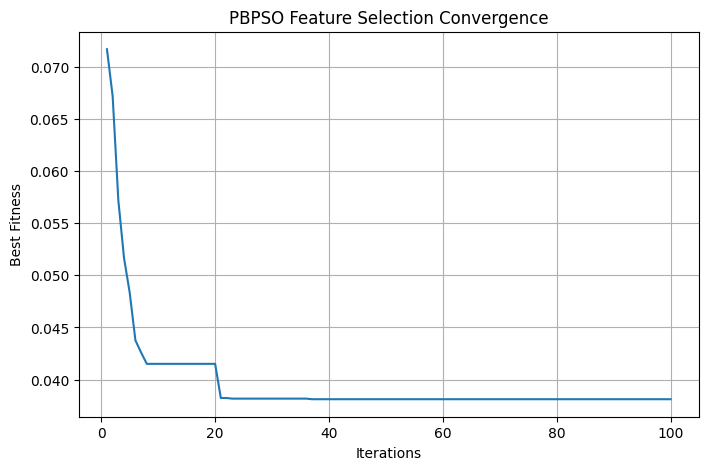

In [1]:

# PARTICLE SWARM OPTIMIZATION FOR FEATURE SELECTION
# Probability-Based Binary PSO (PBPSO)

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

np.random.seed(42)

# 1. Load Dataset
data = load_breast_cancer()
X = data.data
y = data.target
features = data.feature_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

D = X_train.shape[1]

# 2. Parameters
population_size = 50
max_iterations = 100

p0 = 0.05
p1 = 0.35
p2 = 0.65
alpha = 0.9

# 3. Fitness Function
fitness_cache = {}

def fitness(position):

    selected = position.astype(bool)
    key = tuple(position)

    if key in fitness_cache:
        return fitness_cache[key]

    if np.sum(selected) == 0:
        return alpha

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )

    cv = StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train[:, selected],
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    error = 1 - np.mean(scores)

    feature_ratio = np.sum(selected) / D

    result = alpha * error + (1 - alpha) * feature_ratio

    fitness_cache[key] = result

    return result

# 4. Initialize Population
particles = np.random.randint(
    0, 2, (population_size, D)
)

pbest = particles.copy()

pbest_scores = np.array([
    fitness(p) for p in particles
])

best_index = np.argmin(pbest_scores)

gbest = pbest[best_index].copy()
gbest_score = pbest_scores[best_index]

convergence = []

# 5. PBPSO Algorithm
print("Starting PBPSO Feature Selection...\n")

for iteration in range(max_iterations):

    # Evaluate particles and update best solutions
    for i in range(population_size):

        score = fitness(particles[i])

        if score < pbest_scores[i]:
            pbest_scores[i] = score
            pbest[i] = particles[i].copy()

    # Update global best
    best_index = np.argmin(pbest_scores)

    if pbest_scores[best_index] < gbest_score:
        gbest_score = pbest_scores[best_index]
        gbest = pbest[best_index].copy()

    # Update particle positions using flipping probability
    for i in range(population_size):

        personal_difference = particles[i] != pbest[i]
        global_difference = particles[i] != gbest

        probability = (
            p0
            + p1 * personal_difference
            + p2 * global_difference
        )

        random_values = np.random.rand(D)

        flip = random_values < probability

        particles[i] = np.where(
            flip, 1 - particles[i], particles[i]
        )

    convergence.append(gbest_score)

    print(
        "Iteration:", iteration + 1,
        "| Best Fitness:", round(gbest_score, 5)
    )

# 6. Display Selected Features
selected = gbest.astype(bool)

print("\n--- FEATURE SELECTION RESULTS ---")

print("\nSelected Features:")

for feature in features[selected]:
    print(feature)

print("\nTotal Selected Features:", np.sum(selected))
print("Original Features:", D)
print("Best Fitness:", round(gbest_score, 5))

# 7. Train KNN Classifier
model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

model.fit(X_train[:, selected], y_train)

predictions = model.predict(X_test[:, selected])

# 8. Evaluate Selected Features
accuracy = accuracy_score(y_test, predictions)

print("\n--- MODEL PERFORMANCE ---")
print("Selected Feature Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, predictions))

# 9. Compare with All Features
baseline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

print("\n--- PERFORMANCE COMPARISON ---")
print("All Features Accuracy:",
      round(baseline_accuracy * 100, 2), "%")

print("PBPSO Selected Features Accuracy:",
      round(accuracy * 100, 2), "%")

print("Features Reduced:",
      D - np.sum(selected))

# 10. Convergence Graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, max_iterations + 1),
    convergence
)

plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("PBPSO Feature Selection Convergence")

plt.grid(True)
plt.show()
